In [49]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

In [2]:
raw_data = pd.read_excel('./Downloads/default of credit card clients.xls', header=1)

### Data Cleaning

In [3]:
raw_data.head(3)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [4]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [5]:
print('Number of IDs: ', raw_data.shape[0])
print('Unique IDs: ', raw_data.ID.nunique())

Number of IDs:  30000
Unique IDs:  30000


In [6]:
cat_vars = [col for col in raw_data if raw_data[col].nunique() <= 20]
for cat_var in cat_vars:
    print(f'{cat_var}: {raw_data[cat_var].unique()}')

SEX: [2 1]
EDUCATION: [2 1 3 5 4 6 0]
MARRIAGE: [1 2 3 0]
PAY_0: [ 2 -1  0 -2  1  3  4  8  7  5  6]
PAY_2: [ 2  0 -1 -2  3  5  7  4  1  6  8]
PAY_3: [-1  0  2 -2  3  4  6  7  1  5  8]
PAY_4: [-1  0 -2  2  3  4  5  7  6  1  8]
PAY_5: [-2  0 -1  2  3  5  4  7  8  6]
PAY_6: [-2  2  0 -1  3  6  4  7  8  5]
default payment next month: [1 0]


In [7]:
q1, q3 = raw_data['LIMIT_BAL'].quantile(0.25), raw_data['LIMIT_BAL'].quantile(0.75)
IQR = q3 - q1
outlier_mask = (raw_data['LIMIT_BAL'] < q1 - 1.5 * IQR) | (raw_data['LIMIT_BAL'] > q3 + 1.5 * IQR)
data = raw_data[~outlier_mask]

In [8]:
data.shape

(29833, 25)

###  Feature Engineering

In [9]:
data = data.copy()
for n in range(1, 6):
    data[f'monthly_spend{n}'] = data[f'BILL_AMT{n}'] + data[f'PAY_AMT{n}'] - data[f'BILL_AMT{n+1}']

In [10]:
pay_amt_cols = [f'PAY_AMT{i}' for i in range(1, 7)]
data['zero_pay_count'] = (data[pay_amt_cols] == 0).sum(axis=1)

In [11]:
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

data['max_delay'] = data[pay_cols].max(axis=1)
data['months_since_delay'] = data[pay_cols].apply(
    lambda row: next((i for i, v in enumerate(row) if v > 0), 6), axis=1
)
data['paid_in_full_streak'] = data[pay_cols].apply(
    lambda row: next((i for i, v in enumerate(row) if v != -1), 6), axis=1
)

In [12]:
bill_cols = [f'BILL_AMT{i}' for i in range(1, 7)]

data['util_avg'] = data[bill_cols].mean(axis=1) / data['LIMIT_BAL']
data['util_max'] = data[bill_cols].max(axis=1) / data['LIMIT_BAL']
data['delay_x_limit'] = data['PAY_0'].clip(lower=0) * np.log1p(data['LIMIT_BAL'])

In [13]:
pay_amt_cols = [f'PAY_AMT{i}' for i in range(1, 7)]

data['pay_to_bill_avg'] = (
    data[pay_amt_cols].sum(axis=1) / data[bill_cols].sum(axis=1).replace(0, np.nan)
).fillna(0)
data['min_pay_months'] = (
    data[pay_amt_cols].values < 0.05 * data[bill_cols].values
).sum(axis=1)

In [14]:
data['bill_cv'] = (data[bill_cols].std(axis=1) / data[bill_cols].mean(axis=1).replace(0, np.nan)).fillna(0)
data['bill_trend'] = (data['BILL_AMT1'] - data['BILL_AMT6']) / data['LIMIT_BAL']

In [15]:
columns_for_encoding = ['SEX', 'EDUCATION', 'MARRIAGE']
data = pd.get_dummies(data, columns=columns_for_encoding)

In [16]:
data.isna().sum()

ID                            0
LIMIT_BAL                     0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
monthly_spend1                0
monthly_spend2                0
monthly_spend3                0
monthly_spend4                0
monthly_spend5                0
zero_pay_count                0
max_delay                     0
months_since_delay            0
paid_in_full_streak           0
util_avg

### Data Exploration

In [17]:
data.drop(['ID'], axis=1, inplace=True)

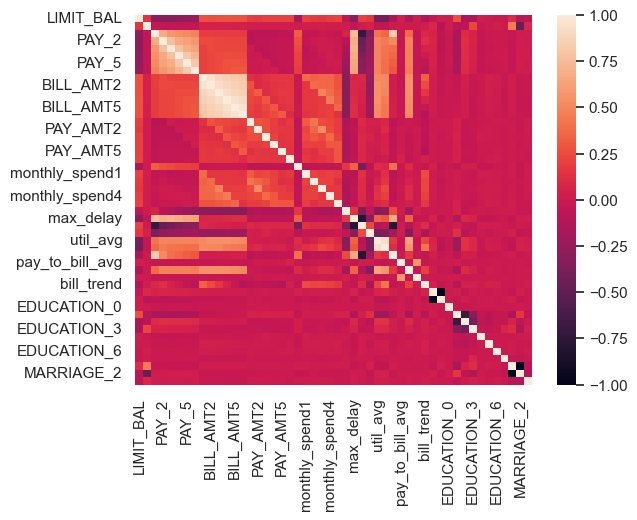

In [18]:
data_corrs = data.corr()
sns.heatmap(data_corrs)
plt.show()

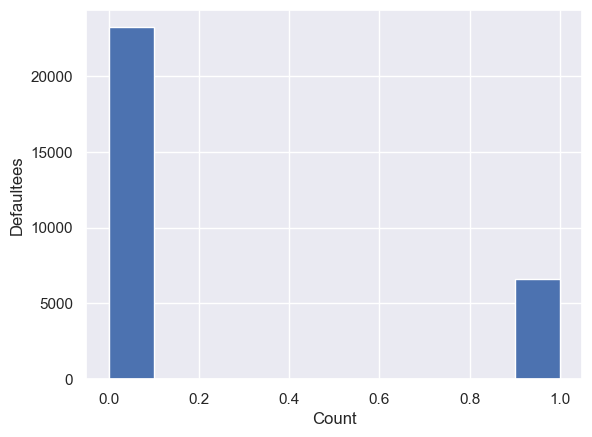

In [19]:
defaultees = data['default payment next month']
plt.hist(defaultees)
plt.xlabel('Count')
plt.ylabel('Defaultees')
plt.show()

### Modelling

In [20]:
test_size = 0.2
x = data.drop(['default payment next month'], axis=1)
y = data['default payment next month']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, stratify=None, random_state=26)

In [21]:
def KS(y_true, y_score):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return np.max(tpr - fpr)

In [39]:
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression())
lr_model.fit(x_train, y_train)
lr_predictions = lr_model.predict(x_test)
lr_proba = lr_model.predict_proba(x_test)[:, 1]

In [41]:
print(f'LR AUC: {roc_auc_score(y_test, lr_proba)}')
print(f'LR Gini: {2 * (roc_auc_score(y_test, lr_proba)) -1}')
print(f'LR KS: {KS(y_test, lr_proba)}')
print(f'LR Precision: {precision_score(y_test, lr_predictions)}')
print(f'LR Recall: {recall_score(y_test, lr_predictions)}')

LR AUC: 0.7870336991641966
LR Gini: 0.5740673983283933
LR KS: 0.43752932559709773
LR Precision: 0.7058823529411765
LR Recall: 0.37719298245614036


In [24]:
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced'))
lr_model.fit(x_train, y_train)
lr_predictions = lr_model.predict(x_test)
lr_proba = lr_model.predict_proba(x_test)[:, 1]

In [38]:
print(f'weighted-LR AUC: {roc_auc_score(y_test, lr_proba)}')
print(f'weighted-LR Gini: {2 * (roc_auc_score(y_test, lr_proba)) -1}')
print(f'weighted-LR KS: {KS(y_test, lr_proba)}')
print(f'weighted-LR Precision: {precision_score(y_test, lr_predictions)}')
print(f'weighted-LR Recall: {recall_score(y_test, lr_predictions)}')

weighted-LR AUC: 0.7891875808242067
weighted-LR Gini: 0.5783751616484134
weighted-LR KS: 0.443224213501791
weighted-LR Precision: 0.48268279274326553
weighted-LR Recall: 0.6418128654970761


In [26]:
rf_model = RandomForestClassifier()
rf_model = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=50,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=26
)
rf_model.fit(x_train, y_train)
rf_prediction = rf_model.predict(x_test)
rf_proba = rf_model.predict_proba(x_test)[:, 1]

In [36]:
print(f'RF AUC: {roc_auc_score(y_test, rf_proba)}')
print(f'RF Gini: {2 * (roc_auc_score(y_test, rf_proba)) -1}')
print(f'RF KS: {KS(y_test,rf_proba)}')
print(f'RF Precision: {precision_score(y_test, rf_prediction)}')
print(f'RF Recall: {recall_score(y_test, rf_prediction)}')

RF AUC: 0.8034889354283732
RF Gini: 0.6069778708567464
RF KS: 0.4663771300397112
RF Precision: 0.5154518950437318
RF Recall: 0.6461988304093568


In [28]:
gb_model = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=26
)
gb_model.fit(x_train, y_train)
gb_predictions = gb_model.predict(x_test)
gb_proba = gb_model.predict_proba(x_test)[:, 1]

In [35]:
print(f'GB AUC: {roc_auc_score(y_test, gb_proba)}')
print(f'GB Gini: {2 * (roc_auc_score(y_test, gb_proba)) -1}')
print(f'GB KS: {KS(y_test, gb_proba)}')
print(f'GB Precision: {precision_score(y_test, gb_predictions)}')
print(f'GB Recall: {recall_score(y_test, gb_predictions)}')

GB AUC: 0.8010965548066006
GB Gini: 0.6021931096132012
GB KS: 0.46191248669619256
GB Precision: 0.4944933920704846
GB Recall: 0.6564327485380117


In [42]:
xgb_model = XGBClassifier(
    n_estimators=400,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=3.5,
    eval_metric='auc',
    random_state=26
)
xgb_model.fit(x_train, y_train)
xgb_predictions = xgb_model.predict(x_test)
xgb_proba = xgb_model.predict_proba(x_test)[:, 1]

In [43]:
print(f'XGB AUC: {roc_auc_score(y_test, xgb_proba)}')
print(f'XGB Gini: {2 * (roc_auc_score(y_test, xgb_proba)) -1}')
print(f'XGB KS: {KS(y_test, xgb_proba)}')
print(f'XGB Precision: {precision_score(y_test, xgb_predictions)}')
print(f'XGB Recall: {recall_score(y_test, xgb_predictions)}')

XGB AUC: 0.8044603358980913
XGB Gini: 0.6089206717961826
XGB KS: 0.4657291058696971
XGB Precision: 0.4988925802879291
XGB Recall: 0.658625730994152


In [30]:
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (gb_proba >= t).astype(int)
    print(f'cutoff {t:.1f}  precision {precision_score(y_test, pred):.3f}  '
          f'recall {recall_score(y_test, pred):.3f}  flagged {pred.mean():.1%}')

cutoff 0.3  precision 0.304  recall 0.911  flagged 68.6%
cutoff 0.4  precision 0.392  recall 0.784  flagged 45.9%
cutoff 0.5  precision 0.494  recall 0.656  flagged 30.4%
cutoff 0.6  precision 0.568  recall 0.572  flagged 23.1%
cutoff 0.7  precision 0.682  recall 0.442  flagged 14.9%


In [31]:
result = permutation_importance(
    gb_model, x_test, y_test,
    scoring='roc_auc', n_repeats=10, random_state=26, n_jobs=-1
)

importance = (
    pd.DataFrame({'feature': x_test.columns,
                  'importance': result.importances_mean,
                  'std': result.importances_std})
    .sort_values('importance', ascending=False)
)

In [45]:
print(importance.head(10))

               feature  importance       std
27  months_since_delay    0.027953  0.002415
30            util_max    0.010652  0.001351
26           max_delay    0.009321  0.001244
31       delay_x_limit    0.003006  0.000782
20      monthly_spend1    0.002674  0.001255
15            PAY_AMT2    0.002574  0.000960
34             bill_cv    0.002145  0.000789
16            PAY_AMT3    0.001885  0.000689
32     pay_to_bill_avg    0.001839  0.000847
25      zero_pay_count    0.001735  0.000312


In [47]:
def evaluate_scores(y_true, y_score):
    auc = roc_auc_score(y_true, y_score)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    ks = np.max(tpr - fpr)
    gini = 2 * auc - 1
    return {'AUC': auc, 'Gini': gini, 'KS': ks}

In [48]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=26)

models = {
    'XGB': XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=4,
                         subsample=0.8, colsample_bytree=0.8,
                         scale_pos_weight=3.5, eval_metric='auc',
                         random_state=26),
    'GB': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                         class_weight='balanced', random_state=26),
    'RF': RandomForestClassifier(n_estimators=500, min_samples_leaf=50,
                                 class_weight='balanced_subsample',
                                 n_jobs=-1, random_state=26),
}

for name, model in models.items():
    fold_results = []
    for tr, va in cv.split(x, y):
        model.fit(x.iloc[tr], y.iloc[tr])
        proba = model.predict_proba(x.iloc[va])[:, 1]
        fold_results.append(evaluate_scores(y.iloc[va], proba))
    print(name, {m: f"{np.mean([r[m] for r in fold_results]):.4f} "
                    f"(+/- {np.std([r[m] for r in fold_results]):.4f})"
                 for m in ['AUC', 'Gini', 'KS']})

XGB {'AUC': '0.7885 (+/- 0.0085)', 'Gini': '0.5771 (+/- 0.0171)', 'KS': '0.4420 (+/- 0.0186)'}
GB {'AUC': '0.7865 (+/- 0.0095)', 'Gini': '0.5731 (+/- 0.0190)', 'KS': '0.4405 (+/- 0.0174)'}
RF {'AUC': '0.7885 (+/- 0.0097)', 'Gini': '0.5770 (+/- 0.0193)', 'KS': '0.4377 (+/- 0.0180)'}
